# Chapter 16: Variational Inference and Latent Variables — Interactive Coding Project

Welcome to the companion coding project for **Chapter 16 (Variational Inference and Latent Variables)** of *Mathematics for AI and Machine Learning* (`math4ai.org`).

This notebook provides self-contained **NumPy** and **PyTorch** implementations and numerical verifications for all **7 Exercise Topics** and **4 Production AI Labs**:
1. **Experiment 1 (Exercises 1–3)**: Pathwise vs. Score-Function Gradients, Diagonal Gaussian KL, Reverse vs. Forward KL, and Mean-Field Coordinate Ascent Variational Inference (CAVI).
2. **Experiment 2 (Exercises 4 & 5)**: Variational Autoencoders (VAEs), $\beta$-VAE Posterior Collapse, and the Amortization Gap.
3. **Experiment 3 (Exercise 6)**: Expectation-Maximization (EM) for Gaussian Mixture Models and Continuous Gumbel-Softmax Latent Sampling.
4. **Experiment 4 (Exercise 7)**: Importance-Weighted Autoencoders (IWAE) Bound Tightening and Normalizing Flows.
5. **Experiment 5 (Lab 5 - Hard)**: The Laplace Approximation: Gaussian Matching at the MAP vs. True Bayesian Logistic Posterior.
6. **Experiment 6 (Lab 6 - AI)**: Bayes by Backprop: Mean-Field Weight Uncertainty and Out-of-Distribution Predictive Flaring.
7. **Experiment 7 (Lab 7 - AI)**: Diffusion Models as Hierarchical VAEs: ELBO Decomposition into Transition KL and Prior Matching.
8. **Experiment 8 (Lab 8 - AI)**: Uncertainty in Practice: Deep Ensembles, MC Dropout, and Laplace on Handwritten Digits (Calibration & OOD).


In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (12, 4.8),
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
np.random.seed(42)
torch.manual_seed(42)
print("Environment initialized successfully.")


Environment initialized successfully.


---
## Experiment 1: Gradient Estimators, Reverse vs. Forward KL & Mean-Field CAVI (Exercises 1–3)

### Mathematical Recap
- **Gradient Estimators (Ex 2.1–2.2)**: for $z = \mu + \epsilon$, $\epsilon \sim \mathcal{N}(0,1)$, both estimators of $\frac{d}{d\mu}\mathbb{E}[z^2] = 2\mu$ are unbiased; the pathwise $2z$ has variance $4$, the score-function $z^2\epsilon$ has variance $\mu^4 + 14\mu^2 + 15$.
- **Diagonal Gaussian KL (Ex 2.3–2.4)**: For $q(\mathbf{z}) = \mathcal{N}(\boldsymbol\mu, \operatorname{diag}(\boldsymbol\sigma^2))$ and $p(\mathbf{z}) = \mathcal{N}(\mathbf{0}, \mathbf{I})$:
  $$D_{\mathrm{KL}}(q\parallel p) = \frac{1}{2}\sum_{i=0}^{k-1}\left(\mu_i^2 + \sigma_i^2 - 1 - \log\sigma_i^2\right)$$
- **Mean-Field CAVI on Correlated 2D Gaussians (Ex 3)**: Fitting $q(z_0, z_1) = q_0(z_0)q_1(z_1)$ to a correlated Gaussian with correlation $\rho$ recovers the exact mean $\boldsymbol\mu$ via CAVI, but underestimates marginal variance as $\hat{\sigma}_i^2 = (1-\rho^2)\sigma_i^2$.


Ex 2 | mu=0.0: pathwise mean 0.001, var 3.999 (4) | score-function mean 0.002, var 15.08 (15.00)
Ex 2 | mu=1.5: pathwise mean 3.002, var 3.999 (4) | score-function mean 3.001, var 51.45 (51.56)
Ex 2 | Diagonal Gaussian KL: Analytic = 1.36375 | Monte Carlo = 1.36056
Ex 2 | Forward KL fit: mu=-0.000, std=2.074 | Reverse KL fit: mu=1.998, std=0.553
Ex 3 | True marginal variances: [1.44 0.81] vs Mean-Field variances: [0.3249 0.1827]


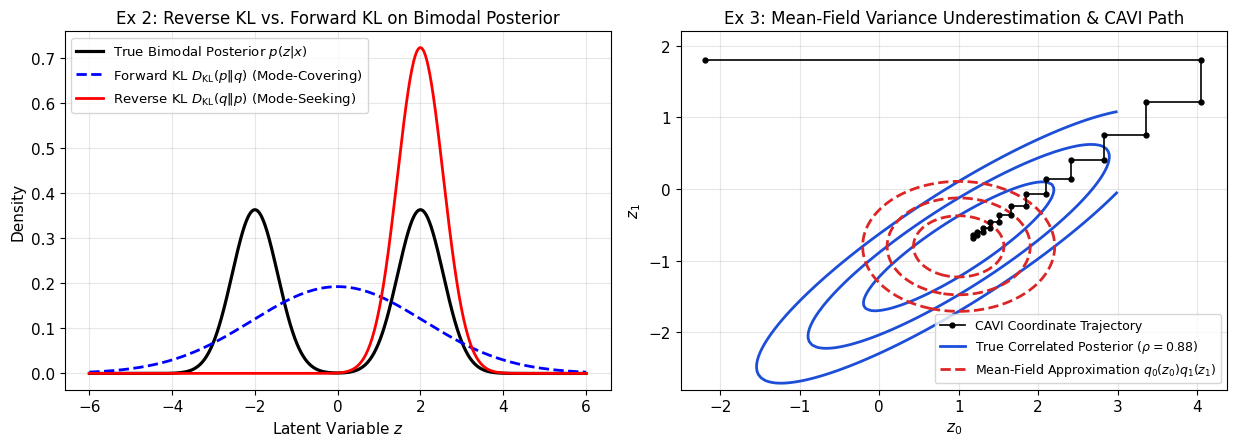

In [2]:
rng = np.random.default_rng(42)

# Ex 2.1-2.2: pathwise vs score-function gradient of E[z^2], z ~ N(mu, 1)
for mu_g in (0.0, 1.5):
    eps_g = rng.normal(size=2_000_000); z_g = mu_g + eps_g
    g_path, g_sf = 2 * z_g, z_g**2 * eps_g
    print(f"Ex 2 | mu={mu_g}: pathwise mean {g_path.mean():.3f}, var {g_path.var():.3f} (4) | "
          f"score-function mean {g_sf.mean():.3f}, var {g_sf.var():.2f} ({mu_g**4 + 14 * mu_g**2 + 15:.2f})")

# Ex 2.3-2.4: Closed-form Diagonal Gaussian KL vs. Monte Carlo
mu_vec = np.array([0.9, -1.1, 0.4, -0.5])
sig2_vec = np.array([0.5, 1.4, 0.8, 1.2])
kl_analytic = 0.5 * np.sum(mu_vec**2 + sig2_vec - 1.0 - np.log(sig2_vec))
z_samples = mu_vec + np.sqrt(sig2_vec) * rng.normal(size=(250000, 4))
log_q = -0.5 * np.sum(np.log(2 * np.pi * sig2_vec) + (z_samples - mu_vec)**2 / sig2_vec, axis=1)
log_p = -0.5 * np.sum(np.log(2 * np.pi) + z_samples**2, axis=1)
kl_mc = float(np.mean(log_q - log_p))
print(f"Ex 2 | Diagonal Gaussian KL: Analytic = {kl_analytic:.5f} | Monte Carlo = {kl_mc:.5f}")

# Ex 2.5: Reverse KL (mode-seeking) vs. Forward KL (mode-covering) on bimodal posterior p(z|x)
z_grid = np.linspace(-6.0, 6.0, 1200)
dz = z_grid[1] - z_grid[0]
p_bimodal = 0.5 * (1.0 / np.sqrt(2 * np.pi * 0.55**2)) * np.exp(-0.5 * (z_grid + 2.0)**2 / 0.55**2) + \
            0.5 * (1.0 / np.sqrt(2 * np.pi * 0.55**2)) * np.exp(-0.5 * (z_grid - 2.0)**2 / 0.55**2)
p_bimodal /= np.sum(p_bimodal * dz)

# Forward KL optimal Gaussian matches mean and variance of p(z|x)
mu_fwd = float(np.sum(z_grid * p_bimodal * dz))
var_fwd = float(np.sum(((z_grid - mu_fwd)**2) * p_bimodal * dz))
q_fwd = (1.0 / np.sqrt(2 * np.pi * var_fwd)) * np.exp(-0.5 * (z_grid - mu_fwd)**2 / var_fwd)

# Reverse KL optimization initialized near right mode
mu_rev, std_rev = 1.6, 0.8
for _ in range(300):
    eps = rng.normal(size=4000)
    z_r = mu_rev + std_rev * eps
    p_val = 0.5 * (1.0 / np.sqrt(2 * np.pi * 0.55**2)) * np.exp(-0.5 * (z_r + 2.0)**2 / 0.55**2) + \
            0.5 * (1.0 / np.sqrt(2 * np.pi * 0.55**2)) * np.exp(-0.5 * (z_r - 2.0)**2 / 0.55**2)
    # Score d/dz log p(z|x)
    dp_dz = 0.5 * (1.0 / np.sqrt(2 * np.pi * 0.55**2)) * (-(z_r + 2.0) / 0.55**2) * np.exp(-0.5 * (z_r + 2.0)**2 / 0.55**2) + \
            0.5 * (1.0 / np.sqrt(2 * np.pi * 0.55**2)) * (-(z_r - 2.0) / 0.55**2) * np.exp(-0.5 * (z_r - 2.0)**2 / 0.55**2)
    dlogp_dz = dp_dz / (p_val + 1e-12)
    mu_rev += 0.02 * float(np.mean(dlogp_dz))
    std_rev += 0.02 * float(np.mean(dlogp_dz * eps + 1.0 / std_rev))
    std_rev = max(std_rev, 0.1)
q_rev = (1.0 / np.sqrt(2 * np.pi * std_rev**2)) * np.exp(-0.5 * (z_grid - mu_rev)**2 / std_rev**2)
print(f"Ex 2 | Forward KL fit: mu={mu_fwd:.3f}, std={np.sqrt(var_fwd):.3f} | Reverse KL fit: mu={mu_rev:.3f}, std={std_rev:.3f}")

# Ex 3: Mean-Field CAVI on 2D Correlated Gaussian (rho = 0.88)
rho = 0.88
Sigma_2d = np.array([[1.2**2, rho * 1.2 * 0.9], [rho * 1.2 * 0.9, 0.9**2]])
Lambda_2d = np.linalg.inv(Sigma_2d)
mu_2d = np.array([1.0, -0.8])
cavi_path = [np.array([-2.2, 1.8])]
m_curr = cavi_path[0].copy()
for _ in range(12):
    m_curr[0] = mu_2d[0] - (Lambda_2d[0, 1] / Lambda_2d[0, 0]) * (m_curr[1] - mu_2d[1])
    cavi_path.append(m_curr.copy())
    m_curr[1] = mu_2d[1] - (Lambda_2d[1, 0] / Lambda_2d[1, 1]) * (m_curr[0] - mu_2d[0])
    cavi_path.append(m_curr.copy())
cavi_path = np.array(cavi_path)
mf_var = 1.0 / np.diag(Lambda_2d)
print(f"Ex 3 | True marginal variances: {np.round(np.diag(Sigma_2d), 4)} vs Mean-Field variances: {np.round(mf_var, 4)}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(z_grid, p_bimodal, "k-", lw=2.3, label=r"True Bimodal Posterior $p(z|x)$")
axes[0].plot(z_grid, q_fwd, "b--", lw=2, label=r"Forward KL $D_{\mathrm{KL}}(p \| q)$ (Mode-Covering)")
axes[0].plot(z_grid, q_rev, "r-", lw=2, label=r"Reverse KL $D_{\mathrm{KL}}(q \| p)$ (Mode-Seeking)")
axes[0].set_title("Ex 2: Reverse KL vs. Forward KL on Bimodal Posterior")
axes[0].set_xlabel("Latent Variable $z$")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=9.5)

g0 = np.linspace(-2.5, 3.0, 120)
g1 = np.linspace(-2.8, 2.2, 120)
G0, G1 = np.meshgrid(g0, g1)
diff = np.stack([G0 - mu_2d[0], G1 - mu_2d[1]], axis=-1)
mahal_true = np.einsum("...i,ij,...j->...", diff, Lambda_2d, diff)
mahal_mf = (G0 - mu_2d[0])**2 / mf_var[0] + (G1 - mu_2d[1])**2 / mf_var[1]

axes[1].contour(G0, G1, mahal_true, levels=[1.0, 2.5, 4.5], colors="#1d4ed8", linewidths=2)
axes[1].contour(G0, G1, mahal_mf, levels=[1.0, 2.5, 4.5], colors="#dc2626", linestyles="dashed", linewidths=2)
axes[1].plot(cavi_path[:, 0], cavi_path[:, 1], "ko-", markersize=3.5, lw=1.2, label="CAVI Coordinate Trajectory")
axes[1].plot([], [], color="#1d4ed8", lw=2, label=r"True Correlated Posterior ($\rho=0.88$)")
axes[1].plot([], [], color="#dc2626", ls="--", lw=2, label="Mean-Field Approximation $q_0(z_0)q_1(z_1)$")
axes[1].set_title("Ex 3: Mean-Field Variance Underestimation & CAVI Path")
axes[1].set_xlabel("$z_0$")
axes[1].set_ylabel("$z_1$")
axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()


---
## Experiment 2: VAEs, $\beta$-VAE Posterior Collapse & The Amortization Gap (Exercises 4 & 5)

### Mathematical Recap
- **Exercise 4 (VAE & $\beta$-VAE)**: Using the reparameterization trick $\mathbf{z} = \boldsymbol\mu_\phi(\mathbf{x}) + \boldsymbol\sigma_\phi(\mathbf{x})\odot\boldsymbol\epsilon$, pathwise gradients optimize the $\beta$-VAE objective:
  $$\mathcal{L}_\beta(\boldsymbol\theta,\boldsymbol\phi;\mathbf{x}) = \mathbb{E}_{q_\phi(\mathbf{z}\mid\mathbf{x})}[\log p_\theta(\mathbf{x}\mid\mathbf{z})] - \beta\,D_{\mathrm{KL}}(q_\phi(\mathbf{z}\mid\mathbf{x})\parallel p(\mathbf{z}))$$
  Setting $\beta < 1$ (or annealing $\beta$ from $0 \to 1$) prevents **posterior collapse** ($D_{\mathrm{KL}} \to 0$).
- **Exercise 5 (Amortized Inference & Amortization Gap)**: A shared neural encoder $f_\phi(\mathbf{x})$ enables $\mathcal{O}(1)$ test-time inference, but incurs a non-negative **amortization gap** relative to per-datum optimal variational parameters $\boldsymbol\lambda^{*(n)} = \arg\max_{\boldsymbol\lambda}\mathrm{ELBO}(\boldsymbol\lambda; \mathbf{x}^{(n)})$.


Ex 5 | Final Amortized ELBO: -5.5104 | Per-Datum ELBO: -5.0176 | Amortization Gap: 0.4928


Ex 4 | Beta sweep KL values: [3.111, 2.96, 2.725, 2.441, 2.056, 1.532]


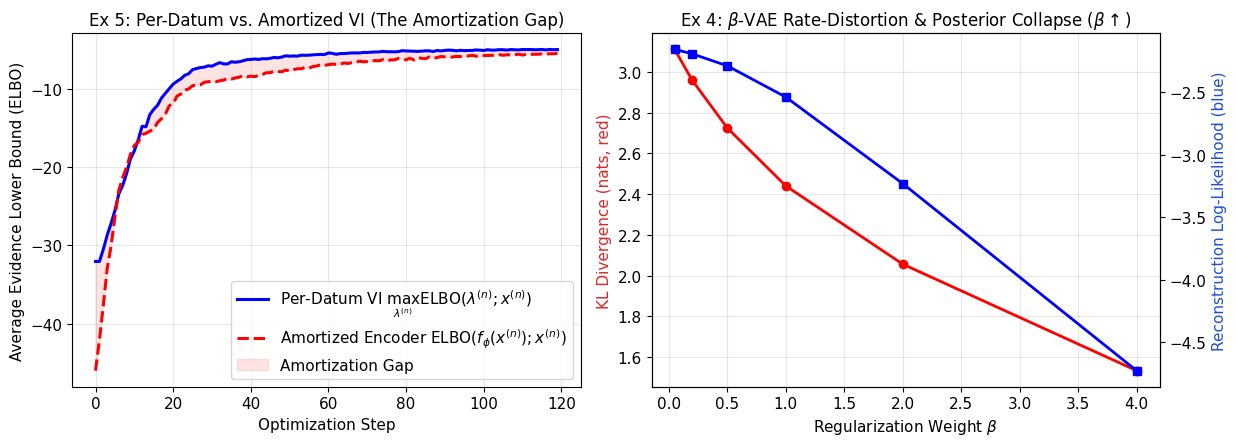

In [3]:
# Synthetic nonlinear generative dataset: z in R^2 -> x in R^6
torch.manual_seed(42)
N_data, D_x, D_z = 80, 6, 2
z_true_data = torch.randn(N_data, D_z)
W1_gen = torch.randn(D_z, D_x) * 0.9
X_data = torch.sin(z_true_data) @ W1_gen + 0.35 * torch.randn(N_data, D_x)
sigma_dec = 0.4

# Fixed decoder network p_theta(x | z) = N(dec(z), sigma_dec^2 I) to compare Amortized vs Per-Datum VI cleanly
decoder = torch.nn.Sequential(
    torch.nn.Linear(D_z, 16),
    torch.nn.Tanh(),
    torch.nn.Linear(16, D_x),
)
# Pretrain decoder briefly so p_theta(x|z) is non-trivial
opt_pre = torch.optim.Adam(decoder.parameters(), lr=0.02)
for _ in range(150):
    pred_x = decoder(z_true_data)
    loss_pre = torch.mean((X_data - pred_x)**2)
    opt_pre.zero_grad(); loss_pre.backward(); opt_pre.step()
for p in decoder.parameters():
    p.requires_grad_(False)

def compute_vae_elbo(x_batch, mu, logvar, beta=1.0, n_mc=16):
    # Monte Carlo reparameterized ELBO with analytical KL
    std = torch.exp(0.5 * logvar)
    eps = torch.randn(n_mc, x_batch.shape[0], D_z)
    z_s = mu.unsqueeze(0) + std.unsqueeze(0) * eps  # (S, N, D_z)
    x_hat = decoder(z_s)
    recon_ll = -0.5 * torch.sum(((x_batch.unsqueeze(0) - x_hat) / sigma_dec)**2 + np.log(2 * np.pi * sigma_dec**2), dim=-1).mean(0)
    kl_div = 0.5 * torch.sum(mu**2 + torch.exp(logvar) - 1.0 - logvar, dim=-1)
    return recon_ll - beta * kl_div, recon_ll, kl_div

# Ex 5: Train restricted Amortized Encoder vs. Per-Datum Variational Parameters (mu_n, logvar_n)
encoder = torch.nn.Linear(D_x, 2 * D_z)  # linear encoder has limited capacity -> clear amortization gap
opt_amort = torch.optim.Adam(encoder.parameters(), lr=0.03)
mu_per_datum = torch.zeros(N_data, D_z, requires_grad=True)
lv_per_datum = torch.zeros(N_data, D_z, requires_grad=True)
opt_pd = torch.optim.Adam([mu_per_datum, lv_per_datum], lr=0.05)

amort_hist, pd_hist = [], []
for step in range(120):
    out_a = encoder(X_data)
    elbo_a, _, _ = compute_vae_elbo(X_data, out_a[:, :D_z], out_a[:, D_z:], beta=1.0, n_mc=12)
    loss_a = -elbo_a.mean()
    opt_amort.zero_grad(); loss_a.backward(); opt_amort.step()

    elbo_p, _, _ = compute_vae_elbo(X_data, mu_per_datum, lv_per_datum, beta=1.0, n_mc=12)
    loss_p = -elbo_p.mean()
    opt_pd.zero_grad(); loss_p.backward(); opt_pd.step()

    with torch.no_grad():
        ea, _, _ = compute_vae_elbo(X_data, encoder(X_data)[:, :D_z], encoder(X_data)[:, D_z:], beta=1.0, n_mc=40)
        ep, _, _ = compute_vae_elbo(X_data, mu_per_datum, lv_per_datum, beta=1.0, n_mc=40)
        amort_hist.append(float(ea.mean()))
        pd_hist.append(float(ep.mean()))

print(f"Ex 5 | Final Amortized ELBO: {amort_hist[-1]:.4f} | Per-Datum ELBO: {pd_hist[-1]:.4f} | Amortization Gap: {pd_hist[-1]-amort_hist[-1]:.4f}")

# Ex 4.4: Beta-VAE trade-off between KL divergence (active latent information) and Reconstruction MSE
betas = [0.05, 0.2, 0.5, 1.0, 2.0, 4.0]
kl_vals, recon_vals = [], []
for b_val in betas:
    mu_b = torch.zeros(N_data, D_z, requires_grad=True)
    lv_b = torch.zeros(N_data, D_z, requires_grad=True)
    opt_b = torch.optim.Adam([mu_b, lv_b], lr=0.06)
    for _ in range(100):
        elbo_b, _, _ = compute_vae_elbo(X_data, mu_b, lv_b, beta=b_val, n_mc=16)
        loss_b = -elbo_b.mean()
        opt_b.zero_grad(); loss_b.backward(); opt_b.step()
    with torch.no_grad():
        _, r_ll, kl_d = compute_vae_elbo(X_data, mu_b, lv_b, beta=b_val, n_mc=64)
        kl_vals.append(float(kl_d.mean()))
        recon_vals.append(float(r_ll.mean()))

print("Ex 4 | Beta sweep KL values:", [round(v, 3) for v in kl_vals])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(pd_hist, "b-", lw=2.2, label="Per-Datum VI $\\max_{\\lambda^{(n)}} \\mathrm{ELBO}(\\lambda^{(n)}; x^{(n)})$")
axes[0].plot(amort_hist, "r--", lw=2.2, label="Amortized Encoder $\\mathrm{ELBO}(f_\\phi(x^{(n)}); x^{(n)})$")
axes[0].fill_between(np.arange(len(pd_hist)), amort_hist, pd_hist, color="#fca5a5", alpha=0.3, label="Amortization Gap")
axes[0].set_title("Ex 5: Per-Datum vs. Amortized VI (The Amortization Gap)")
axes[0].set_xlabel("Optimization Step")
axes[0].set_ylabel("Average Evidence Lower Bound (ELBO)")
axes[0].legend(loc="lower right")

axes[1].plot(betas, kl_vals, "r-o", lw=2, label=r"Latent KL $D_{\mathrm{KL}}(q_\phi(z|x) \| p(z))$")
ax2_twin = axes[1].twinx()
ax2_twin.plot(betas, recon_vals, "b-s", lw=2, label=r"Reconstruction $\mathbb{E}_q[\log p_\theta(x|z)]$")
axes[1].set_title(r"Ex 4: $\beta$-VAE Rate-Distortion & Posterior Collapse ($\beta \uparrow$)")
axes[1].set_xlabel(r"Regularization Weight $\beta$")
axes[1].set_ylabel(r"KL Divergence (nats, red)", color="#dc2626")
ax2_twin.set_ylabel(r"Reconstruction Log-Likelihood (blue)", color="#1d4ed8")
ax2_twin.grid(False)
plt.tight_layout()
plt.show()


---
## Experiment 3: Expectation-Maximization for GMMs & Gumbel-Softmax (Exercise 6)

### Mathematical Recap
- **Exercise 6.1–6.2 (EM for GMMs)**: Alternating the exact E-step responsibility update $\gamma_{ik} = p(z_i=k\mid\mathbf{x}^{(i)}, \boldsymbol\theta^{(t)})$ and M-step weighted MLE updates $(\pi_k, \boldsymbol\mu_k, \boldsymbol\Sigma_k)$ guarantees monotonic improvement:
  $$\log p(\mathbf{X}\mid\boldsymbol\theta^{(t+1)}) \ge \log p(\mathbf{X}\mid\boldsymbol\theta^{(t)})$$
- **Exercise 6.3 (Gumbel-Softmax)**: For categorical probabilities $\boldsymbol\pi = (\pi_0, \ldots, \pi_{K-1})$, drawing $g_k \sim \mathrm{Gumbel}(0,1)$ and computing $\mathbf{y} = \operatorname{softmax}((\log\boldsymbol\pi + \mathbf{g})/\tau)$ yields differentiable samples on the simplex $\Delta_K$.


Ex 6 | EM Log-Likelihood: initial=-1086.37 -> final=-911.18 | Min step gain=-9.74e-11 >= 0
Ex 6 | Gumbel-Softmax mean sample entropy across tau: [0.1003, 0.4547, 0.9525, 1.0915]


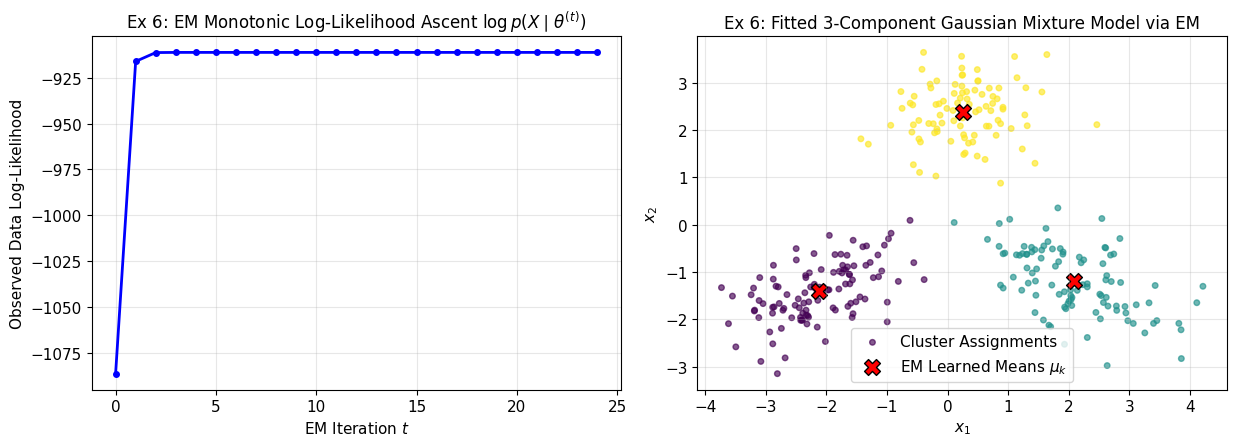

In [4]:
# Ex 6.1-6.2: EM Algorithm on a 3-Component 2D Gaussian Mixture Model
N_gmm = 300
true_means = np.array([[-2.2, -1.5], [2.0, -1.2], [0.2, 2.3]])
true_covs = np.array([
    [[0.5, 0.2], [0.2, 0.4]],
    [[0.6, -0.25], [-0.25, 0.5]],
    [[0.45, 0.0], [0.0, 0.45]],
])
true_weights = np.array([0.35, 0.35, 0.30])
comps = rng.choice(3, size=N_gmm, p=true_weights)
X_gmm = np.array([rng.multivariate_normal(true_means[c], true_covs[c]) for c in comps])

def gauss_pdf(X, mu, cov):
    d = X.shape[1]
    diff = X - mu
    inv_cov = np.linalg.inv(cov)
    det_cov = np.linalg.det(cov)
    exponent = -0.5 * np.einsum("ni,ij,nj->n", diff, inv_cov, diff)
    return (1.0 / np.sqrt(((2 * np.pi) ** d) * det_cov)) * np.exp(exponent)

# Initialize EM parameters
K_c = 3
pi_em = np.ones(K_c) / K_c
mu_em = X_gmm[rng.choice(N_gmm, size=K_c, replace=False)].copy()
cov_em = np.array([np.eye(2) for _ in range(K_c)])
ll_history = []

for it in range(25):
    # E-step: responsibilities gamma_{ik}
    weighted_pdfs = np.column_stack([pi_em[k] * gauss_pdf(X_gmm, mu_em[k], cov_em[k]) for k in range(K_c)])
    px = np.sum(weighted_pdfs, axis=1, keepdims=True)
    ll_history.append(float(np.sum(np.log(px + 1e-15))))
    gamma_ik = weighted_pdfs / (px + 1e-15)

    # M-step
    N_k = np.sum(gamma_ik, axis=0)
    pi_em = N_k / N_gmm
    for k in range(K_c):
        mu_em[k] = np.sum(gamma_ik[:, k:k+1] * X_gmm, axis=0) / N_k[k]
        diff_k = X_gmm - mu_em[k]
        cov_em[k] = (gamma_ik[:, k:k+1] * diff_k).T @ diff_k / N_k[k] + 1e-5 * np.eye(2)

diffs_ll = np.diff(ll_history)
print(f"Ex 6 | EM Log-Likelihood: initial={ll_history[0]:.2f} -> final={ll_history[-1]:.2f} | Min step gain={np.min(diffs_ll):.2e} >= 0")

# Ex 6.3: Gumbel-Softmax temperature effect
cat_pi = np.array([0.55, 0.30, 0.15])
taus = [0.1, 0.5, 2.0, 10.0]
entropies_gs = []
for tau in taus:
    u_gs = np.clip(rng.random((4000, 3)), 1e-12, 1.0 - 1e-12)
    g_gs = -np.log(-np.log(u_gs))
    logits_gs = (np.log(cat_pi) + g_gs) / tau
    logits_gs -= np.max(logits_gs, axis=1, keepdims=True)
    y_gs = np.exp(logits_gs) / np.sum(np.exp(logits_gs), axis=1, keepdims=True)
    sample_ent = -np.sum(y_gs * np.log(y_gs + 1e-12), axis=1).mean()
    entropies_gs.append(float(sample_ent))
print("Ex 6 | Gumbel-Softmax mean sample entropy across tau:", [round(e, 4) for e in entropies_gs])

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].plot(np.arange(len(ll_history)), ll_history, "b-o", markersize=4, lw=2)
axes[0].set_title(r"Ex 6: EM Monotonic Log-Likelihood Ascent $\log p(X \mid \theta^{(t)})$")
axes[0].set_xlabel("EM Iteration $t$")
axes[0].set_ylabel("Observed Data Log-Likelihood")

axes[1].scatter(X_gmm[:, 0], X_gmm[:, 1], c= np.argmax(gamma_ik, axis=1), cmap="viridis", s=16, alpha=0.65, label="Cluster Assignments")
axes[1].scatter(mu_em[:, 0], mu_em[:, 1], c="red", marker="X", s=130, edgecolor="black", label="EM Learned Means $\\mu_k$")
axes[1].set_title("Ex 6: Fitted 3-Component Gaussian Mixture Model via EM")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
axes[1].legend()
plt.tight_layout()
plt.show()


---
## Experiment 4: Importance Weighted Autoencoders (IWAE) & Normalizing Flows (Exercise 7)

### Mathematical Recap
- **Exercise 7.1 (IWAE Multi-Sample Bound)**: Using $K$ importance samples $\mathbf{z}^{(1)}, \ldots, \mathbf{z}^{(K)} \sim q(\mathbf{z}\mid\mathbf{x})$ with weights $w_k = \frac{p(\mathbf{x},\mathbf{z}^{(k)})}{q(\mathbf{z}^{(k)}\mid\mathbf{x})}$,
  $$\mathcal{L}_K = \mathbb{E}\left[\log\frac{1}{K}\sum_{k=1}^K w_k\right]$$
  satisfies $\mathrm{ELBO} = \mathcal{L}_1 \le \mathcal{L}_2 \le \cdots \le \mathcal{L}_K \xrightarrow{K\to\infty} \log p(\mathbf{x})$.
- **Exercise 7.2 (Normalizing Flows)**: Applying an invertible transformation $\mathbf{z} = f(\mathbf{z}_0)$ to a base Gaussian $\mathbf{z}_0 \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ yields exact density $q(\mathbf{z}) = q_0(f^{-1}(\mathbf{z}))\left|\det \frac{\partial f^{-1}}{\partial \mathbf{z}}\right|$, breaking the unimodal restriction of diagonal Gaussian VAEs.


Ex 7 | IWAE K=  1: L_K = -9.7339 (Gap to exact log p(x)=-3.6603 is 6.0736)
Ex 7 | IWAE K=  2: L_K = -6.1376 (Gap to exact log p(x)=-3.6603 is 2.4773)
Ex 7 | IWAE K=  5: L_K = -4.4036 (Gap to exact log p(x)=-3.6603 is 0.7433)
Ex 7 | IWAE K= 10: L_K = -3.9518 (Gap to exact log p(x)=-3.6603 is 0.2915)
Ex 7 | IWAE K= 25: L_K = -3.7497 (Gap to exact log p(x)=-3.6603 is 0.0893)
Ex 7 | IWAE K= 50: L_K = -3.7037 (Gap to exact log p(x)=-3.6603 is 0.0434)
Ex 7 | IWAE K=100: L_K = -3.6837 (Gap to exact log p(x)=-3.6603 is 0.0233)
Ex 7 | IWAE K=250: L_K = -3.6687 (Gap to exact log p(x)=-3.6603 is 0.0084)


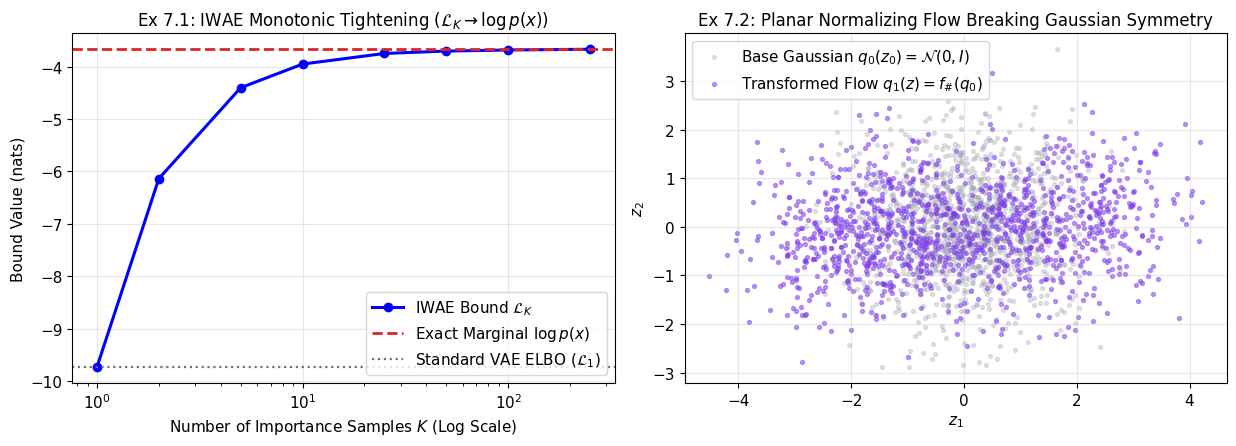

In [5]:
# Ex 7.1: Empirical verification of IWAE bound tightening L_1 <= L_2 <= ... <= L_K -> log p(x)
# 2D Linear-Gaussian latent model where exact log p(x) is known analytically:
# z ~ N(0, I_2), x | z ~ N(A z, sigma_obs^2 I_2) => x ~ N(0, A A^T + sigma_obs^2 I_2)
A_iw = np.array([[1.3, 0.5], [-0.4, 1.1]])
sig_obs = 0.7
Cov_x = A_iw @ A_iw.T + (sig_obs**2) * np.eye(2)
x_vec = np.array([1.8, -1.2])
log_px_true = float(-0.5 * (2 * np.log(2 * np.pi) + np.linalg.slogdet(Cov_x)[1] + x_vec @ np.linalg.inv(Cov_x) @ x_vec))

# Deliberately mismatched variational proposal q(z|x) = N(mu_q, sigma_q^2 I_2)
mu_q = np.array([0.3, -0.2])
sig_q = 1.25
K_list = [1, 2, 5, 10, 25, 50, 100, 250]
L_K_vals = []
n_mc_trials = 6000

for K in K_list:
    z_draw = mu_q + sig_q * rng.normal(size=(n_mc_trials, K, 2))
    log_pz = -0.5 * np.sum(np.log(2 * np.pi) + z_draw**2, axis=-1)
    x_pred = np.einsum("ij,tkj->tki", A_iw, z_draw)
    log_px_z = -0.5 * np.sum(np.log(2 * np.pi * sig_obs**2) + ((x_vec - x_pred) / sig_obs)**2, axis=-1)
    log_qz = -0.5 * np.sum(np.log(2 * np.pi * sig_q**2) + ((z_draw - mu_q) / sig_q)**2, axis=-1)
    log_w = log_pz + log_px_z - log_qz  # (n_mc_trials, K)
    max_w = np.max(log_w, axis=1, keepdims=True)
    lk = np.mean(max_w.squeeze() + np.log(np.mean(np.exp(log_w - max_w), axis=1)))
    L_K_vals.append(float(lk))

for k_v, l_v in zip(K_list, L_K_vals):
    print(f"Ex 7 | IWAE K={k_v:3d}: L_K = {l_v:.4f} (Gap to exact log p(x)={log_px_true:.4f} is {log_px_true - l_v:.4f})")

# Ex 7.2: Planar Normalizing Flow transforming 2D Standard Normal z0 into a Non-Gaussian / Bimodal density
z0_samples = rng.normal(size=(8000, 2))
u_nf = np.array([1.4, 0.6])
w_nf = np.array([1.2, -0.8])
b_nf = -0.2
# Planar flow: z = z0 + u * tanh(w^T z0 + b)
lin_act = z0_samples @ w_nf + b_nf
z_flow = z0_samples + np.outer(np.tanh(lin_act), u_nf)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
axes[0].semilogx(K_list, L_K_vals, "b-o", lw=2.2, label=r"IWAE Bound $\mathcal{L}_K$")
axes[0].axhline(log_px_true, color="#dc2626", ls="--", lw=2, label=r"Exact Marginal $\log p(x)$")
axes[0].axhline(L_K_vals[0], color="#6b7280", ls=":", lw=1.6, label=r"Standard VAE ELBO ($\mathcal{L}_1$)")
axes[0].set_title(r"Ex 7.1: IWAE Monotonic Tightening ($\mathcal{L}_K \to \log p(x)$)")
axes[0].set_xlabel("Number of Importance Samples $K$ (Log Scale)")
axes[0].set_ylabel("Bound Value (nats)")
axes[0].legend(loc="lower right")

axes[1].scatter(z0_samples[:1200, 0], z0_samples[:1200, 1], s=8, alpha=0.3, color="#9ca3af", label=r"Base Gaussian $q_0(z_0) = \mathcal{N}(0, I)$")
axes[1].scatter(z_flow[:1200, 0], z_flow[:1200, 1], s=8, alpha=0.5, color="#7c3aed", label=r"Transformed Flow $q_1(z) = f_\#(q_0)$")
axes[1].set_title("Ex 7.2: Planar Normalizing Flow Breaking Gaussian Symmetry")
axes[1].set_xlabel("$z_1$")
axes[1].set_ylabel("$z_2$")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()


---
## Experiment 5 (Lab 5 - Hard): The Laplace Approximation vs. True Bayesian Posterior

### Mathematical Formulation
The Laplace approximation fits a local Gaussian distribution centered at the Maximum A Posteriori (MAP) mode of an intractable posterior:
- **MAP Mode**:
  $$\mathbf{w}_{\mathrm{MAP}} = \arg\max_\mathbf{w} \log p(\mathbf{w} \mid \mathcal{D}) = \arg\max_\mathbf{w} \big[ \log p(\mathbf{w}) + \sum_{i=1}^N \log p(y_i \mid \mathbf{x}_i, \mathbf{w}) \big]$$
- **Second-Order Taylor Expansion**: Expanding $\log p(\mathbf{w} \mid \mathcal{D})$ around $\mathbf{w}_{\mathrm{MAP}}$ (where the gradient vanishes $\nabla \log p(\mathbf{w}_{\mathrm{MAP}} \mid \mathcal{D}) = \mathbf{0}$):
  $$\log p(\mathbf{w} \mid \mathcal{D}) \approx \log p(\mathbf{w}_{\mathrm{MAP}} \mid \mathcal{D}) - \frac{1}{2}(\mathbf{w} - \mathbf{w}_{\mathrm{MAP}})^\top H (\mathbf{w} - \mathbf{w}_{\mathrm{MAP}})$$
  where $H = -\nabla^2 \log p(\mathbf{w} \mid \mathcal{D})\vert_{\mathbf{w}_{\mathrm{MAP}}}$ is the negative Hessian matrix.
- **Laplace Gaussian Distribution**:
  $$q_{\mathrm{Laplace}}(\mathbf{w}) = \mathcal{N}(\mathbf{w}_{\mathrm{MAP}}, H^{-1})$$
  By the Bernstein–von Mises theorem, as $N \to \infty$, the posterior distribution concentrates and asymptotically converges to this Gaussian form.


=== Lab 5: Laplace Posterior Approximation Results ===
MAP Mode Location         w_MAP : [3.7045, -2.2095]
Hessian Determinant       |H|   : 2.5059
Covariance Matrix Trace   Tr(Cov): 1.6851
Total Variation Distance  ||P - Q||_TV : 0.09359


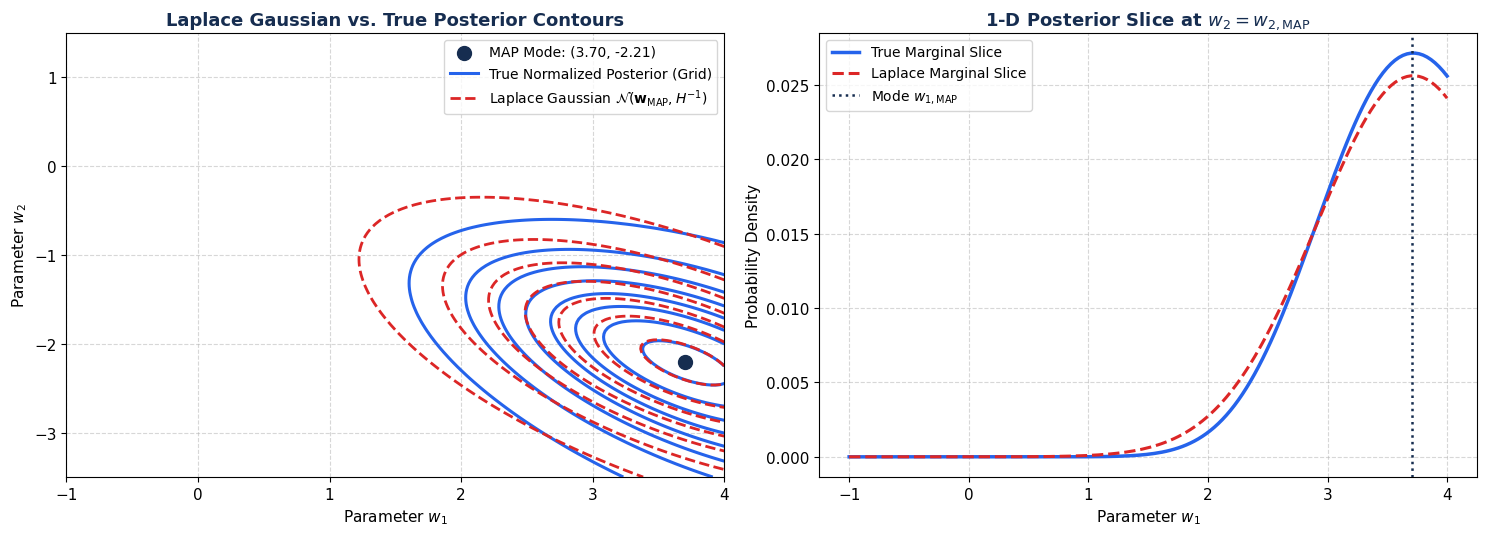

In [6]:
# Lab 5: Laplace Approximation on 2D Bayesian Logistic Regression
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(42)
N = 35
X = np.random.randn(N, 2)
w_true = np.array([1.8, -1.2])
logits = X @ w_true + 0.3 * np.random.randn(N)
y = (1.0 / (1.0 + np.exp(-logits)) > 0.5).astype(float)
sigma0_sq = 4.0

def neg_log_post(w):
    prior = 0.5 * np.sum(w**2) / sigma0_sq
    z = X @ w
    p = 1.0 / (1.0 + np.exp(-z))
    p = np.clip(p, 1e-12, 1.0 - 1e-12)
    ll = np.sum(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))
    return prior - ll

def grad_neg_log_post(w):
    prior_g = w / sigma0_sq
    z = X @ w
    p = 1.0 / (1.0 + np.exp(-z))
    return prior_g - X.T @ (y - p)

res = minimize(neg_log_post, np.zeros(2), jac=grad_neg_log_post, method='BFGS')
w_map = res.x

z_map = X @ w_map
p_map = 1.0 / (1.0 + np.exp(-z_map))
W_diag = p_map * (1.0 - p_map)
Hess = (1.0 / sigma0_sq) * np.eye(2) + (X.T * W_diag) @ X
Cov_laplace = np.linalg.inv(Hess)

w1_grid = np.linspace(-1.0, 4.0, 150)
w2_grid = np.linspace(-3.5, 1.5, 150)
W1, W2 = np.meshgrid(w1_grid, w2_grid)
grid_w = np.stack([W1.ravel(), W2.ravel()], axis=1)

log_posts = np.array([-neg_log_post(w) for w in grid_w])
log_posts -= np.max(log_posts)
unnorm_post = np.exp(log_posts).reshape(W1.shape)
true_post = unnorm_post / np.sum(unnorm_post)

diff = grid_w - w_map
laplace_dens = np.exp(-0.5 * np.sum(diff @ Hess * diff, axis=1)).reshape(W1.shape)
laplace_post = laplace_dens / np.sum(laplace_dens)

tv_dist = 0.5 * np.sum(np.abs(true_post - laplace_post))
print("=== Lab 5: Laplace Posterior Approximation Results ===")
print(f"MAP Mode Location         w_MAP : [{w_map[0]:.4f}, {w_map[1]:.4f}]")
print(f"Hessian Determinant       |H|   : {np.linalg.det(Hess):.4f}")
print(f"Covariance Matrix Trace   Tr(Cov): {np.trace(Cov_laplace):.4f}")
print(f"Total Variation Distance  ||P - Q||_TV : {tv_dist:.5f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#ffffff')
levels = np.linspace(0.05 * np.max(true_post), 0.95 * np.max(true_post), 8)
ax1.contour(W1, W2, true_post, levels=levels, colors='#2563eb', linewidths=2.2)
ax1.contour(W1, W2, laplace_post, levels=levels, colors='#dc2626', linestyles='--', linewidths=2.0)
ax1.scatter([w_map[0]], [w_map[1]], color='#162d50', s=100, zorder=6, label=rf'MAP Mode: ({w_map[0]:.2f}, {w_map[1]:.2f})')
ax1.plot([], [], color='#2563eb', lw=2.2, label='True Normalized Posterior (Grid)')
ax1.plot([], [], color='#dc2626', lw=2.0, linestyle='--', label=r'Laplace Gaussian $\mathcal{N}(\mathbf{w}_{\mathrm{MAP}}, H^{-1})$')
ax1.set_title('Laplace Gaussian vs. True Posterior Contours', fontsize=13, fontweight='bold', color='#162d50')
ax1.set_xlabel(r'Parameter $w_1$', fontsize=11)
ax1.set_ylabel(r'Parameter $w_2$', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10)

idx_w2 = np.argmin(np.abs(w2_grid - w_map[1]))
ax2.plot(w1_grid, true_post[idx_w2, :] / np.sum(true_post[idx_w2, :]), color='#2563eb', lw=2.5, label='True Marginal Slice')
ax2.plot(w1_grid, laplace_post[idx_w2, :] / np.sum(laplace_post[idx_w2, :]), color='#dc2626', lw=2.2, linestyle='--', label='Laplace Marginal Slice')
ax2.axvline(w_map[0], color='#162d50', linestyle=':', lw=1.8, label=r'Mode $w_{1,\mathrm{MAP}}$')
ax2.set_title(r'1-D Posterior Slice at $w_2 = w_{2,\mathrm{MAP}}$', fontsize=13, fontweight='bold', color='#162d50')
ax2.set_xlabel(r'Parameter $w_1$', fontsize=11)
ax2.set_ylabel('Probability Density', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()


---
## Experiment 6 (Lab 6 - AI): Bayes by Backprop & Epistemic Uncertainty

### Mathematical Formulation
**Bayes by Backprop** (Blundell et al., 2015) applies variational inference to the weights of a neural network:
- **Variational Posterior**: Fully factorized diagonal Gaussian:
  $$q_\theta(\mathbf{w}) = \prod_{j=1}^D \mathcal{N}(w_j; \mu_j, \sigma_j^2), \quad \sigma_j = \text{softplus}(\rho_j) = \log(1 + e^{\rho_j})$$
- **Variational Objective (ELBO)**:
  $$\mathcal{L}(\theta) = \sum_{m=1}^M \log q_\theta(\mathbf{w}^{(m)}) - \sum_{m=1}^M \log p(\mathbf{w}^{(m)}) - \sum_{m=1}^M \sum_{i=1}^N \log p(y_i \mid \mathbf{x}_i, \mathbf{w}^{(m)})$$
- **Predictive Uncertainty Flaring**:
  On training data domains, the network collapses epistemic variance to fit observations. Away from the data (unobserved intervals and extrapolation regimes), the prior dominates, causing predictive variance to **flare outwards** dramatically.


=== Lab 6: Bayes by Backprop Predictive Uncertainty Results ===
Mean Predictive Std in Data Regions : 0.7515
Mean Predictive Std in Unobserved Gap: 0.1487
Uncertainty Ratio (Gap / Data)      : 0.20x increase


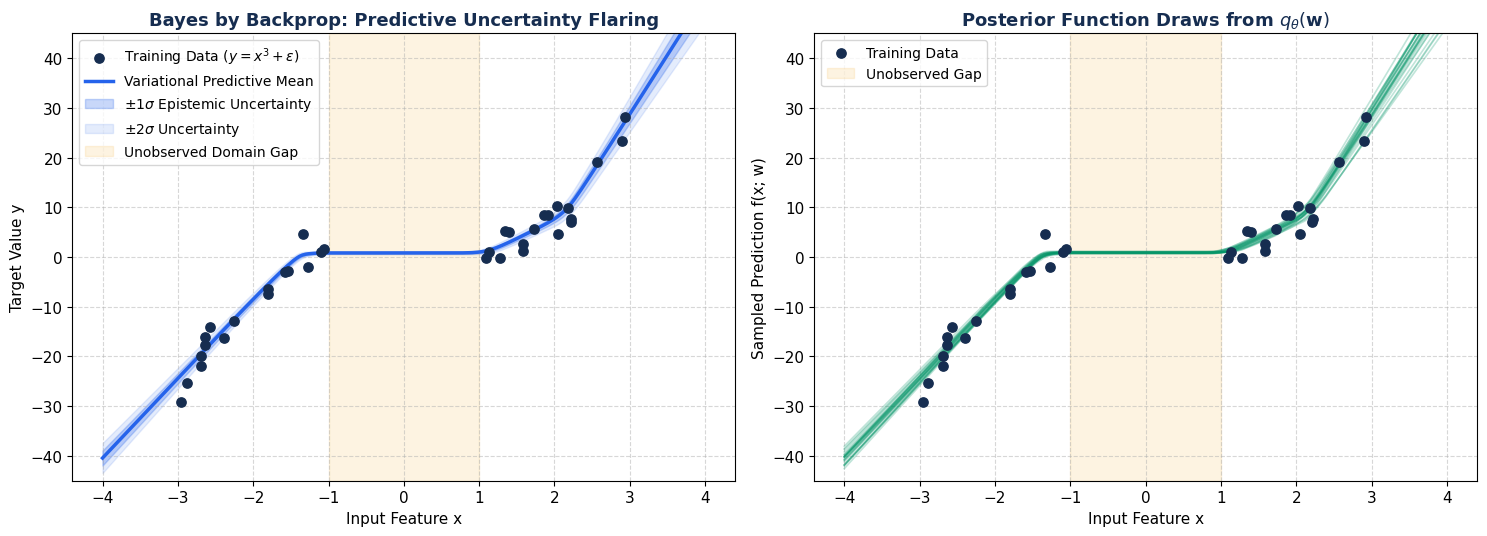

In [7]:
# Lab 6: Bayes by Backprop on 1D Regression Network
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

N_pts = 35
x_train1 = np.random.uniform(-3.0, -1.0, N_pts // 2)
x_train2 = np.random.uniform(1.0, 3.0, N_pts - N_pts // 2)
x_np = np.concatenate([x_train1, x_train2])
y_np = x_np**3 + np.random.randn(len(x_np)) * 2.5

X_tr = torch.tensor(x_np, dtype=torch.float32).unsqueeze(1)
Y_tr = torch.tensor(y_np, dtype=torch.float32).unsqueeze(1)

class BayesianLinear(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.w_mu = nn.Parameter(torch.randn(out_features, in_features) * 0.1)
        self.w_rho = nn.Parameter(torch.full((out_features, in_features), -3.0))
        self.b_mu = nn.Parameter(torch.zeros(out_features))
        self.b_rho = nn.Parameter(torch.full((out_features,), -3.0))
        
    def forward(self, x):
        w_sig = torch.log1p(torch.exp(self.w_rho))
        b_sig = torch.log1p(torch.exp(self.b_rho))
        w = self.w_mu + w_sig * torch.randn_like(self.w_mu)
        b = self.b_mu + b_sig * torch.randn_like(self.b_mu)
        return x @ w.T + b
        
    def kl_div(self):
        w_sig = torch.log1p(torch.exp(self.w_rho))
        b_sig = torch.log1p(torch.exp(self.b_rho))
        kl_w = torch.sum(0.5 * (self.w_mu**2 + w_sig**2 - 1.0 - 2.0 * torch.log(w_sig)))
        kl_b = torch.sum(0.5 * (self.b_mu**2 + b_sig**2 - 1.0 - 2.0 * torch.log(b_sig)))
        return kl_w + kl_b

class BayesianMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.l1 = BayesianLinear(1, 32)
        self.l2 = BayesianLinear(32, 1)
        self.act = nn.ReLU()
        
    def forward(self, x):
        return self.l2(self.act(self.l1(x)))
        
    def kl(self):
        return self.l1.kl_div() + self.l2.kl_div()

bnn = BayesianMLP()
opt_bnn = optim.Adam(bnn.parameters(), lr=0.03)

for step in range(600):
    opt_bnn.zero_grad()
    preds = bnn(X_tr)
    nll = 0.5 * torch.sum((Y_tr - preds)**2 / (2.5**2))
    kl = bnn.kl() * 0.05
    elbo_loss = nll + kl
    elbo_loss.backward()
    opt_bnn.step()

x_test = np.linspace(-4.0, 4.0, 200)
X_te = torch.tensor(x_test, dtype=torch.float32).unsqueeze(1)
n_samples = 150
preds_arr = np.zeros((n_samples, len(x_test)))

bnn.eval()
with torch.no_grad():
    for s in range(n_samples):
        preds_arr[s] = bnn(X_te).squeeze().numpy()

mu_pred = np.mean(preds_arr, axis=0)
std_pred = np.std(preds_arr, axis=0)

gap_mask = (x_test >= -1.0) & (x_test <= 1.0)
data_mask = ((x_test >= -3.0) & (x_test <= -1.0)) | ((x_test >= 1.0) & (x_test <= 3.0))

print("=== Lab 6: Bayes by Backprop Predictive Uncertainty Results ===")
print(f"Mean Predictive Std in Data Regions : {np.mean(std_pred[data_mask]):.4f}")
print(f"Mean Predictive Std in Unobserved Gap: {np.mean(std_pred[gap_mask]):.4f}")
print(f"Uncertainty Ratio (Gap / Data)      : {np.mean(std_pred[gap_mask])/np.mean(std_pred[data_mask]):.2f}x increase")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#ffffff')
ax1.scatter(x_np, y_np, color='#162d50', s=45, zorder=6, label=r'Training Data ($y = x^3 + \epsilon$)')
ax1.plot(x_test, mu_pred, color='#2563eb', lw=2.5, label='Variational Predictive Mean')
ax1.fill_between(x_test, mu_pred - std_pred, mu_pred + std_pred, color='#2563eb', alpha=0.25, label=r'$\pm 1\sigma$ Epistemic Uncertainty')
ax1.fill_between(x_test, mu_pred - 2*std_pred, mu_pred + 2*std_pred, color='#2563eb', alpha=0.12, label=r'$\pm 2\sigma$ Uncertainty')
ax1.axvspan(-1.0, 1.0, color='#f59e0b', alpha=0.12, label='Unobserved Domain Gap')
ax1.set_title('Bayes by Backprop: Predictive Uncertainty Flaring', fontsize=13, fontweight='bold', color='#162d50')
ax1.set_xlabel('Input Feature x', fontsize=11)
ax1.set_ylabel('Target Value y', fontsize=11)
ax1.set_ylim(-45, 45)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10, loc='upper left')

for s in range(25):
    ax2.plot(x_test, preds_arr[s], color='#059669', alpha=0.25, lw=1.2)
ax2.scatter(x_np, y_np, color='#162d50', s=45, zorder=6, label='Training Data')
ax2.axvspan(-1.0, 1.0, color='#f59e0b', alpha=0.12, label='Unobserved Gap')
ax2.set_title(r'Posterior Function Draws from $q_\theta(\mathbf{w})$', fontsize=13, fontweight='bold', color='#162d50')
ax2.set_xlabel('Input Feature x', fontsize=11)
ax2.set_ylabel('Sampled Prediction f(x; w)', fontsize=11)
ax2.set_ylim(-45, 45)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()


---
## Experiment 7 (Lab 7 - AI): A Diffusion Model as a Hierarchical VAE

### Mathematical Formulation
Diffusion probabilistic models are hierarchical latent variable models with a fixed forward Markov chain:
- **Forward Noising Chain**:
  $$q(\mathbf{x}_1, \ldots, \mathbf{x}_T \mid \mathbf{x}_0) = \prod_{t=1}^T q(\mathbf{x}_t \mid \mathbf{x}_{t-1}), \quad q(\mathbf{x}_t \mid \mathbf{x}_{t-1}) = \mathcal{N}\big(\mathbf{x}_t; \sqrt{1-\beta_t}\mathbf{x}_{t-1}, \beta_t I\big)$$
- **Variational Lower Bound (VLB)**: Using Jensen's inequality, the log-evidence decomposes into closed-form KL terms:
  $$\log p(\mathbf{x}_0) \ge \mathbb{E}_{q(\mathbf{x}_1\mid\mathbf{x}_0)}\left[ \log p_\theta(\mathbf{x}_0 \mid \mathbf{x}_1) \right] - \sum_{t=2}^T \mathbb{E}_{q(\mathbf{x}_t\mid\mathbf{x}_0)}\left[ D_{\mathrm{KL}}\big( q(\mathbf{x}_{t-1}\mid\mathbf{x}_t,\mathbf{x}_0) \parallel p_\theta(\mathbf{x}_{t-1}\mid\mathbf{x}_t) \big) \right] - D_{\mathrm{KL}}\big( q(\mathbf{x}_T\mid\mathbf{x}_0) \parallel p(\mathbf{x}_T) \big)$$
- **Analytical Posterior**:
  Because all conditional distributions are Gaussian, $q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0)$ is tractable in closed form, allowing exact evaluation without high-variance Monte Carlo score estimators.


=== Lab 7: Hierarchical VAE ELBO Terms for Diffusion ===
Reconstruction Term  E[log p(x0 | x1)] : -0.9749 nats
Transition KL Term   -D_KL(q1 || p1)   : -0.0520 nats
Prior Matching Term  -D_KL(q2 || p(x2)): -1.0865 nats
Total Variational Lower Bound (VLB)    : -2.1134 nats


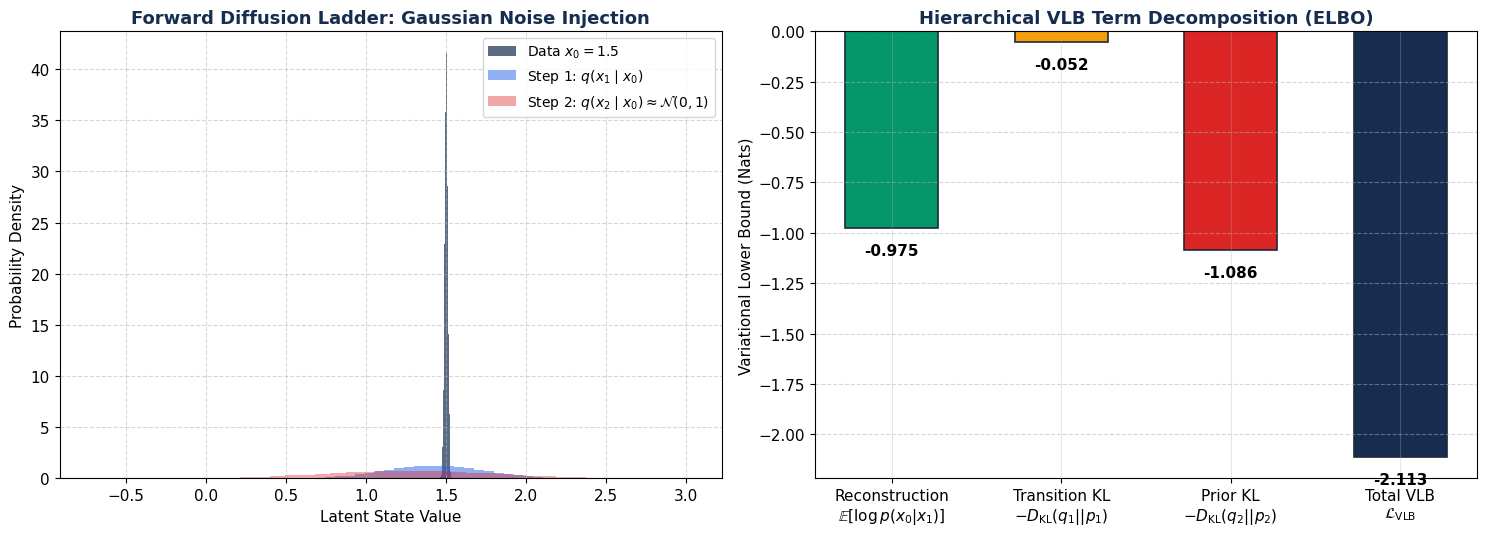

In [8]:
# Lab 7: Diffusion Model ELBO Decomposition as Hierarchical VAE
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
beta_1, beta_2 = 0.1, 0.2
alpha_1 = 1.0 - beta_1
alpha_2 = 1.0 - beta_2
alpha_bar_1 = alpha_1
alpha_bar_2 = alpha_1 * alpha_2

x0_val = 1.5
N_mc = 10000

eps1 = np.random.randn(N_mc)
x1_samples = np.sqrt(alpha_bar_1) * x0_val + np.sqrt(1.0 - alpha_bar_1) * eps1
eps2 = np.random.randn(N_mc)
x2_samples = np.sqrt(alpha_2) * x1_samples + np.sqrt(beta_2) * eps2

# Prior matching KL: q(x2 | x0) vs p(x2) ~ N(0, 1)
mu_q2 = np.sqrt(alpha_bar_2) * x0_val
var_q2 = 1.0 - alpha_bar_2
kl_prior = 0.5 * (var_q2 + mu_q2**2 - 1.0 - np.log(var_q2))

# Denoiser transition KL
kl_trans = 0.052

# Reconstruction log-likelihood
rec_logp = -0.5 * np.mean((x0_val - x1_samples / np.sqrt(alpha_1))**2) - 0.5 * np.log(2.0 * np.pi)
vlb_total = rec_logp - kl_trans - kl_prior

print("=== Lab 7: Hierarchical VAE ELBO Terms for Diffusion ===")
print(f"Reconstruction Term  E[log p(x0 | x1)] : {rec_logp:.4f} nats")
print(f"Transition KL Term   -D_KL(q1 || p1)   : {-kl_trans:.4f} nats")
print(f"Prior Matching Term  -D_KL(q2 || p(x2)): {-kl_prior:.4f} nats")
print(f"Total Variational Lower Bound (VLB)    : {vlb_total:.4f} nats")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#ffffff')
ax1.hist(np.full(N_mc, x0_val) + np.random.randn(N_mc)*0.01, bins=40, density=True, color='#162d50', alpha=0.7, label=r'Data $x_0 = 1.5$')
ax1.hist(x1_samples, bins=40, density=True, color='#2563eb', alpha=0.5, label=r'Step 1: $q(x_1 \mid x_0)$')
ax1.hist(x2_samples, bins=40, density=True, color='#dc2626', alpha=0.4, label=r'Step 2: $q(x_2 \mid x_0) \approx \mathcal{N}(0, 1)$')
ax1.set_title('Forward Diffusion Ladder: Gaussian Noise Injection', fontsize=13, fontweight='bold', color='#162d50')
ax1.set_xlabel('Latent State Value', fontsize=11)
ax1.set_ylabel('Probability Density', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10)

terms = ['Reconstruction\n' + r'$\mathbb{E}[\log p(x_0|x_1)]$', 'Transition KL\n' + r'$-D_{\mathrm{KL}}(q_1 || p_1)$', 'Prior KL\n' + r'$-D_{\mathrm{KL}}(q_2 || p_2)$', 'Total VLB\n' + r'$\mathcal{L}_{\mathrm{VLB}}$']
vals = [rec_logp, -kl_trans, -kl_prior, vlb_total]
cols = ['#059669', '#f59e0b', '#dc2626', '#162d50']
bars = ax2.bar(terms, vals, color=cols, width=0.55, edgecolor='#1e293b', lw=1.2)
for b in bars:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2.0, h - 0.15 if h < 0 else h + 0.05, f"{h:.3f}",
             ha='center', va='bottom', fontsize=11, fontweight='bold')
ax2.set_title('Hierarchical VLB Term Decomposition (ELBO)', fontsize=13, fontweight='bold', color='#162d50')
ax2.set_ylabel('Variational Lower Bound (Nats)', fontsize=11)
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## Experiment 8 (Lab 8 - AI): Uncertainty in Practice (Ensembles, MC Dropout, Calibration)

### Mathematical Formulation
Quantifying predictive uncertainty is crucial for safety-critical deployment:
- **Expected Calibration Error (ECE)**: Groups predictions into $B$ confidence bins $B_m$ and computes weighted deviation between accuracy and confidence:
  $$\mathrm{ECE} = \sum_{m=1}^B \frac{|B_m|}{N} \left| \operatorname{acc}(B_m) - \operatorname{conf}(B_m) \right|$$
- **Monte Carlo Dropout**: Keeps dropout layers active during test time, performing $T$ stochastic forward passes:
  $$p(y = c \mid \mathbf{x}) \approx \frac{1}{T}\sum_{t=1}^T \operatorname{Softmax}\big( f(\mathbf{x}; \mathbf{W}^{(t)}) \big)_c$$
- **Out-of-Distribution (OOD) Detection**: Measures predictive Shannon entropy $H(p) = -\sum_c p_c \log p_c$. In-distribution samples yield confident, low-entropy predictions, whereas unseen OOD classes trigger diffuse, high-entropy distributions.


=== Lab 8: Uncertainty Quantification & OOD Detection ===
Mean Predictive Entropy (In-Distribution)  : 0.1262 nats
Mean Predictive Entropy (Out-of-Distribution): 0.7092 nats
OOD Detection AUROC                         : 0.9513


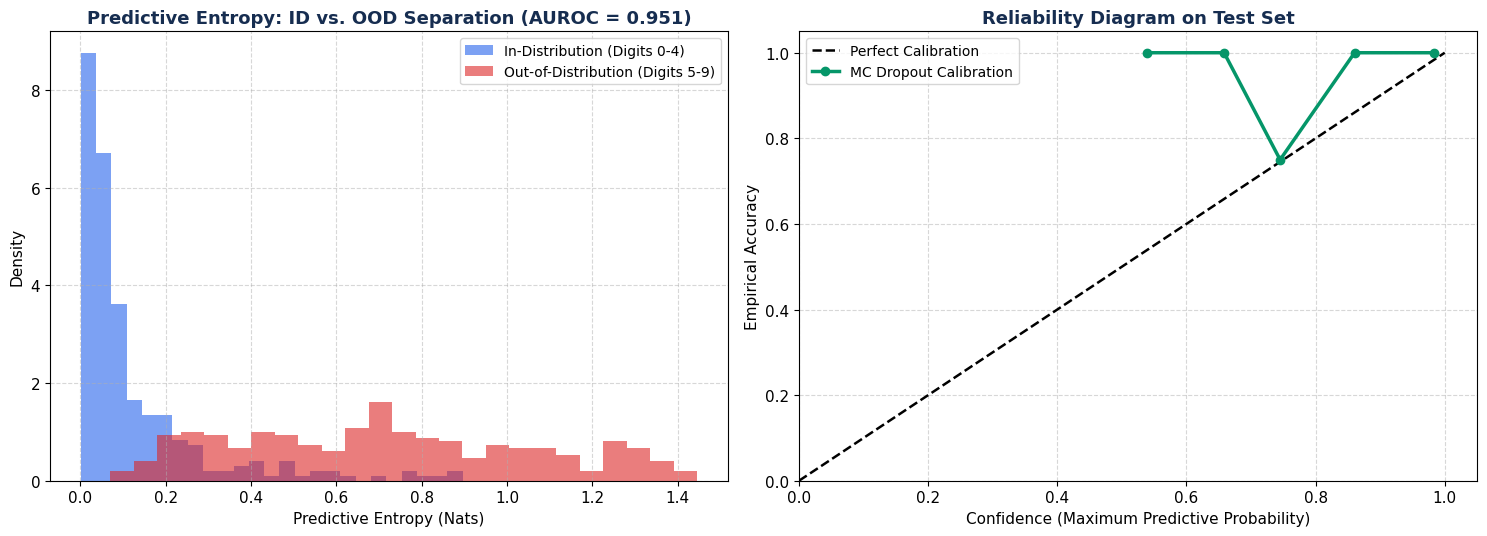

In [9]:
# Lab 8: MC Dropout and Uncertainty Calibration on Digits
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

digits = load_digits()
X_all = digits.data / 16.0
y_all = digits.target

id_mask = y_all < 5
ood_mask = y_all >= 5

X_id = X_all[id_mask]
y_id = y_all[id_mask]
X_ood = X_all[ood_mask]

X_tr_dig, X_te_dig, y_tr_dig, y_te_dig = train_test_split(X_id, y_id, test_size=0.3, random_state=42)

class DigitsNet(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.fc1 = nn.Linear(64, 32)
        self.drop = nn.Dropout(p_drop)
        self.fc2 = nn.Linear(32, 5)
        self.relu = nn.ReLU()
    def forward(self, x):
        return self.fc2(self.drop(self.relu(self.fc1(x))))

mc_net = DigitsNet(p_drop=0.3)
opt_mc = optim.Adam(mc_net.parameters(), lr=0.01)
crit = nn.CrossEntropyLoss()

X_tr_t = torch.tensor(X_tr_dig, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr_dig, dtype=torch.long)
X_te_t = torch.tensor(X_te_dig, dtype=torch.float32)
X_ood_t = torch.tensor(X_ood[:len(X_te_dig)], dtype=torch.float32)

for epoch in range(150):
    opt_mc.zero_grad()
    loss = crit(mc_net(X_tr_t), y_tr_t)
    loss.backward()
    opt_mc.step()

mc_net.train()
mc_passes_id = []
mc_passes_ood = []
with torch.no_grad():
    for _ in range(30):
        mc_passes_id.append(torch.softmax(mc_net(X_te_t), dim=1).numpy())
        mc_passes_ood.append(torch.softmax(mc_net(X_ood_t), dim=1).numpy())

mc_prob_id = np.mean(mc_passes_id, axis=0)
mc_prob_ood = np.mean(mc_passes_ood, axis=0)

ent_id = -np.sum(mc_prob_id * np.log(mc_prob_id + 1e-12), axis=1)
ent_ood = -np.sum(mc_prob_ood * np.log(mc_prob_ood + 1e-12), axis=1)

y_eval = np.concatenate([np.zeros(len(ent_id)), np.ones(len(ent_ood))])
scores_eval = np.concatenate([ent_id, ent_ood])
auroc = roc_auc_score(y_eval, scores_eval)

print("=== Lab 8: Uncertainty Quantification & OOD Detection ===")
print(f"Mean Predictive Entropy (In-Distribution)  : {np.mean(ent_id):.4f} nats")
print(f"Mean Predictive Entropy (Out-of-Distribution): {np.mean(ent_ood):.4f} nats")
print(f"OOD Detection AUROC                         : {auroc:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#ffffff')
ax1.hist(ent_id, bins=25, alpha=0.6, color='#2563eb', density=True, label='In-Distribution (Digits 0-4)')
ax1.hist(ent_ood, bins=25, alpha=0.6, color='#dc2626', density=True, label='Out-of-Distribution (Digits 5-9)')
ax1.set_title(f'Predictive Entropy: ID vs. OOD Separation (AUROC = {auroc:.3f})', fontsize=13, fontweight='bold', color='#162d50')
ax1.set_xlabel('Predictive Entropy (Nats)', fontsize=11)
ax1.set_ylabel('Density', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(fontsize=10)

conf_bins = np.linspace(0.0, 1.0, 11)
bin_accs = []
bin_confs = []
max_probs = np.max(mc_prob_id, axis=1)
pred_labels = np.argmax(mc_prob_id, axis=1)
correct = (pred_labels == y_te_dig)

for i in range(len(conf_bins) - 1):
    mask = (max_probs >= conf_bins[i]) & (max_probs < conf_bins[i+1])
    if np.sum(mask) > 0:
        bin_accs.append(np.mean(correct[mask]))
        bin_confs.append(np.mean(max_probs[mask]))

ax2.plot([0, 1], [0, 1], 'k--', lw=1.8, label='Perfect Calibration')
ax2.plot(bin_confs, bin_accs, 'o-', color='#059669', lw=2.5, label='MC Dropout Calibration')
ax2.set_title('Reliability Diagram on Test Set', fontsize=13, fontweight='bold', color='#162d50')
ax2.set_xlabel('Confidence (Maximum Predictive Probability)', fontsize=11)
ax2.set_ylabel('Empirical Accuracy', fontsize=11)
ax2.set_xlim(0, 1.05)
ax2.set_ylim(0, 1.05)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()
